In [5]:
from pathlib import Path

# --- edit these -------------------------------------------------------
DATA_DIR   = Path("/DATA1/Roxana/Data/MX")
VOCAB_PATH = Path("/DATA1/Roxana/Hierarchy/Two_levels/default_gene_vocab.json")
CHECKPOINT = Path("/DATA1/Roxana/hebi_repo/notebooks/hebi_hybrid_oldL0.pt")
#CHECKPOINT = Path("/DATA1/Roxana/Hierarchy/Two_levels/hebi_continual_k30_norm.pt")
WORK_DIR   = Path("./crossplatform_breast_pretrained")
# ----------------------------------------------------------------------
SECTION_NAMES = ["xenium", "merscope"]
# Two platforms with near-disjoint panels (128 shared genes). Each slide is
# encoded on its native panel; this order is the order every downstream
# list follows.
SECTIONS = [
    ("xenium",   "Xenium_V1_FFPE_Human_Breast_IDC_With_Addon_outs"),
    ("merscope", "HumanBreastCancerPatient1_region_0"),
]

H5AD_FILES    = [DATA_DIR / f"{stem}.h5ad" for _, stem in SECTIONS]
SECTION_FILES = [f"{stem}.pt" for _, stem in SECTIONS]
LABELS        = [label for label, _ in SECTIONS]

PROCESSED_DIR = "crossplatform_breast/processed"
RESULTS_DIR   = WORK_DIR / "results"
#PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# No ground truth across platforms: scoring is annotation-free (FIDE, JSD).
ANNOTATION = None

MODE       = "continual"
NUM_EPOCHS = 10
LR         = 1e-4
NUM_NICHES = 7          # working resolution; FIDE/JSD also at 10 and 15

for path in H5AD_FILES:
    print(f"{'found  ' if path.exists() else 'MISSING'} {path.name}")

found   Xenium_V1_FFPE_Human_Breast_IDC_With_Addon_outs.h5ad
found   HumanBreastCancerPatient1_region_0.h5ad


In [6]:
from hebi.inference.pipeline import encode_sections

sections, ctx = encode_sections(
    checkpoint_path=str(CHECKPOINT),
    data_dir=str(PROCESSED_DIR),
    section_files=SECTION_FILES,
    h5ad_files=[str(p) for p in H5AD_FILES],
    vocab_path=str(VOCAB_PATH),
    section_labels=LABELS,

    mode=MODE,
    init="pretrained",
    num_epochs=NUM_EPOCHS,
    lr=LR,

    grn=False,
    species="Human",

    output_dir=str(RESULTS_DIR),
    seed=2025,
)

Seed set to 2025
Loading /DATA1/Roxana/Data/MX/Xenium_V1_FFPE_Human_Breast_IDC_With_Addon_outs.h5ad


/home/tower4/miniconda3/envs/hebi/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: Some cells have zero counts
  return fn(*args_all, **kw)


Covered genes: 368/380 (96.84%)
  576963 cells, 368 genes
Loading /DATA1/Roxana/Data/MX/HumanBreastCancerPatient1_region_0.h5ad


/home/tower4/miniconda3/envs/hebi/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: Some cells have zero counts
  return fn(*args_all, **kw)


Covered genes: 500/500 (100.00%)
  713121 cells, 500 genes
  Xenium_V1_FFPE_Human_Breast_IDC_With_Addon_outs.pt: 576963 -> 537182 cells matched to the .pt by coordinate
  HumanBreastCancerPatient1_region_0.pt: 713121 -> 639380 cells matched to the .pt by coordinate

Loading checkpoint: /DATA1/Roxana/hebi_repo/notebooks/hebi_hybrid_oldL0.pt
Re-initialising niche-level modules
Orthogonal init for niche prototypes
Fresh optimiser state for continual adaptation

Continual adaptation: 10 epochs over 2 sections
  epoch   1  loss  4.9924  (227s)
  epoch   2  loss  4.1772  (223s)
  epoch   3  loss  3.8393  (217s)
  epoch   4  loss  3.6532  (213s)
  epoch   5  loss  3.5506  (202s)
  epoch   6  loss  3.3736  (199s)
  epoch   7  loss  3.2211  (208s)
  epoch   8  loss  3.0938  (208s)
  epoch   9  loss  3.0131  (208s)
  epoch  10  loss  2.9481  (209s)

Continual adaptation finished. Final loss: 2.9481
🎲 Seed set to 0
--- Using device: cuda:0 ---
📁 Found 2 slides in crossplatform_breast/processed
📦 

Encoding crossplatform_breast/processed/Xenium_V1_FFPE_Human_Breast_IDC_With_Add


📦 Loading preprocessed slide from crossplatform_breast/processed/HumanBreastCancerPatient1_region_0.pt
✅ Loaded data: X=torch.Size([639380, 500]), coords=torch.Size([639380, 2]), edge_index=torch.Size([2, 20811796])


Encoding crossplatform_breast/processed/HumanBreastCancerPatient1_region_0.pt: 1


  1,176,562 cells encoded; 14/20 prototypes in use


In [7]:
adata = sections[0]
print("representations:", [k for k in adata.obsm if k.startswith("z")])
print("prototypes:     ", adata.obs["prototypes"].nunique(), "in use")
print()
print(adata.obsm["z0"].shape, "cell-level embedding")

representations: ['z0', 'z1', 'z2']
prototypes:      13 in use

(537182, 128) cell-level embedding


📦 Loading preprocessed slide from crossplatform_breast/processed/Xenium_V1_FFPE_Human_Breast_IDC_With_Addon_outs.pt
✅ Loaded data: X=torch.Size([537182, 368]), coords=torch.Size([537182, 2]), edge_index=torch.Size([2, 17610570])
📦 Loading preprocessed slide from crossplatform_breast/processed/HumanBreastCancerPatient1_region_0.pt
✅ Loaded data: X=torch.Size([639380, 500]), coords=torch.Size([639380, 2]), edge_index=torch.Size([2, 20811796])
niche_k7: 7 niches (Xenium 6, MERSCOPE 5) | 14 prototypes, 7 merges


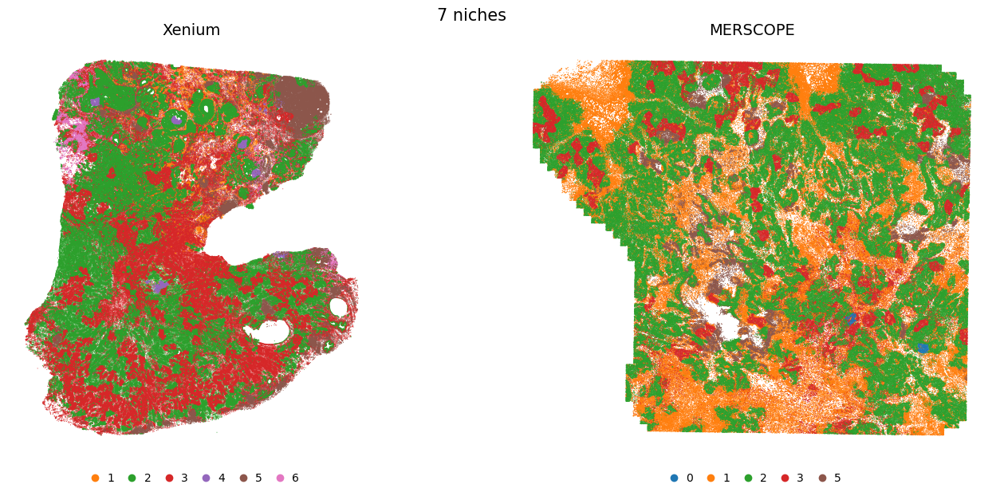

[<Figure size 1400x700 with 2 Axes>]

In [27]:
from hebi.inference.niches import assign_niches, plot_niches

assign_niches(sections, ctx, PROCESSED_DIR, SECTION_FILES, n_niches=7,
              section_names=["Xenium", "MERSCOPE"], cache_dir=RESULTS_DIR)
plot_niches(sections, 7, ["Xenium", "MERSCOPE"], out=RESULTS_DIR / "niches")

niche_k10: 10 niches (Xenium 9, MERSCOPE 6) | 14 prototypes, 4 merges


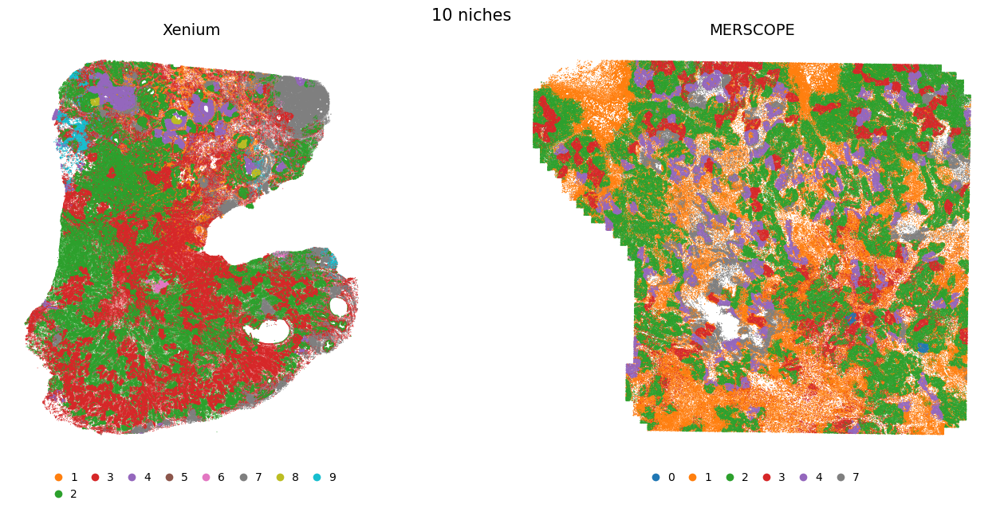

[<Figure size 1400x700 with 2 Axes>]

In [28]:
from hebi.inference.niches import assign_niches, plot_niches

assign_niches(sections, ctx, PROCESSED_DIR, SECTION_FILES, n_niches=10,
              section_names=["Xenium", "MERSCOPE"], cache_dir=RESULTS_DIR)
plot_niches(sections, 10, ["Xenium", "MERSCOPE"], out=RESULTS_DIR / "niches")

niche_k15: 15 niches (Xenium 14, MERSCOPE 11) | 14 prototypes, 1 splits


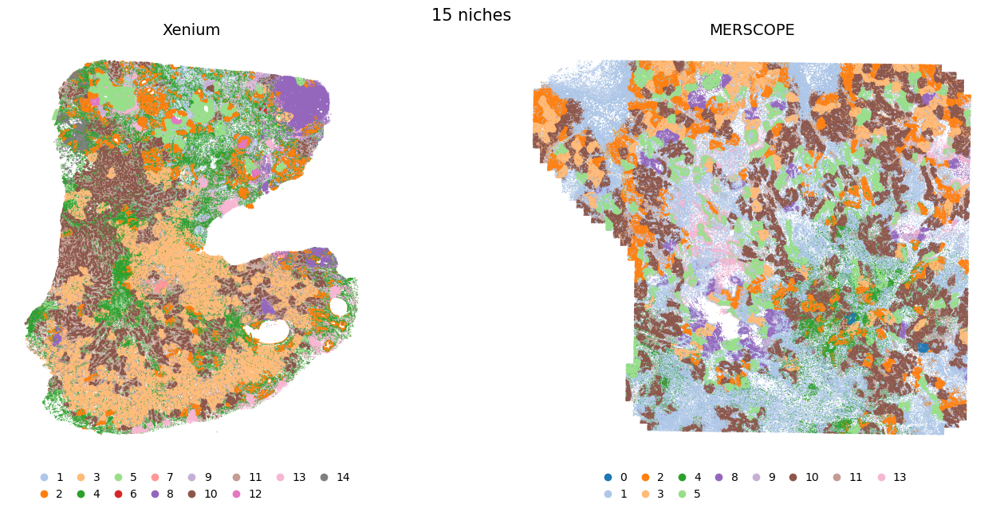

[<Figure size 1400x700 with 2 Axes>]

In [29]:
from hebi.inference.niches import assign_niches, plot_niches

assign_niches(sections, ctx, PROCESSED_DIR, SECTION_FILES, n_niches=15,
              section_names=["Xenium", "MERSCOPE"], cache_dir=RESULTS_DIR)
plot_niches(sections, 15, ["Xenium", "MERSCOPE"], out=RESULTS_DIR / "niches")

In [8]:
from hebi.inference.pipeline import cluster_sections

written = cluster_sections(
    sections, ctx,
    n_cell_clusters=7,
    n_composition_niches=7,
    composition_neighbors=200,
    cluster_method="kmeans",
    cell_type_key=None,
    niche_key=None,
    point_size=6,
)
print("\nwritten:", written)


Cell-level clustering: kmeans, k=7  ->  obs['z0_kmeans_7']
Niche-level clustering: 7 niches from 200-neighbour composition  ->  obs['comp_niches_7']

xenium
  z0_kmeans_7            FIDE=0.5542
  prototypes             FIDE=0.8433
  comp_niches_7          FIDE=0.9724
merscope
  z0_kmeans_7            FIDE=0.4576
  prototypes             FIDE=0.8319
  comp_niches_7          FIDE=0.9644

  Saved z0_kmeans_7 (s=6.0)
  Saved comp_niches_7 (s=6.0)

written: {'cell_clusters': 'z0_kmeans_7', 'composition_niches': 'comp_niches_7'}


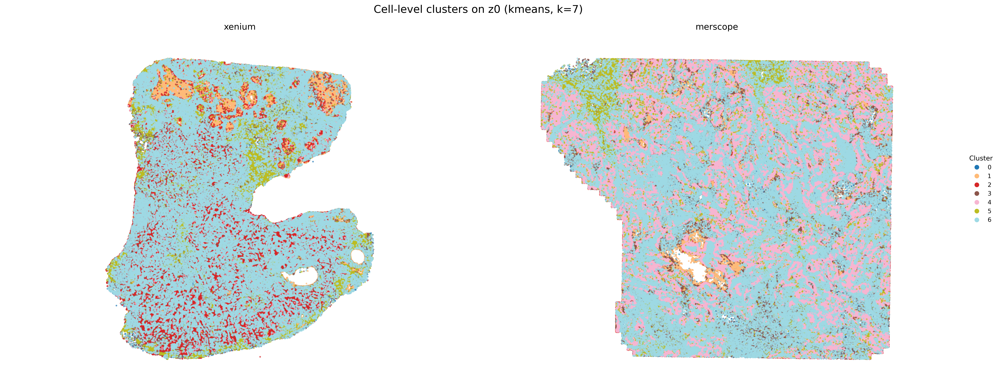

In [9]:
from IPython.display import Image, display

display(Image(filename=str(RESULTS_DIR / f"{written['cell_clusters']}.png")))

section 0: 13 in use | missing: ['1']
section 1: 10 in use | missing: ['9', '10', '16', '19']


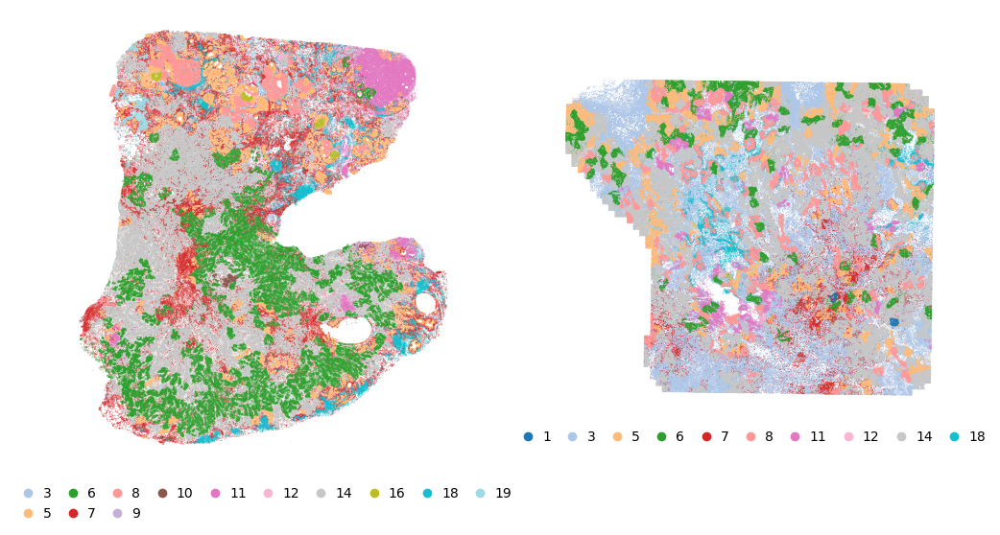

            section 0  section 1
prototypes                      
1                   0        949
3               14739     189231
5               58311      77384
6              129703      51945
7               84815      29927
8               24666      67173
9                 174          0
10               1320          0
11              28025      18457
12               1119       1002
14             154798     186285
16               1962          0
18              28278      17027
19               9272          0


In [10]:
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib, pandas as pd, numpy as np
from matplotlib.lines import Line2D
%matplotlib inline

proto_key = "prototypes"
cats = sorted(set().union(*[set(a.obs[proto_key].astype(str)) for a in sections]),
              key=lambda s: (len(s), s))
cmap = plt.get_cmap("tab20" if len(cats) <= 20 else "gist_ncar", len(cats))
colors = [matplotlib.colors.to_hex(cmap(i)) for i in range(len(cats))]
col_of = dict(zip(cats, colors))

for a in sections:
    a.obs[proto_key] = pd.Categorical(a.obs[proto_key].astype(str), categories=cats)
    a.uns[f"{proto_key}_colors"] = colors

fig, axes = plt.subplots(1, len(sections), figsize=(6 * len(sections), 7))
for i, (a, ax) in enumerate(zip(sections, axes)):
    present = [c for c in cats if (a.obs[proto_key] == c).any()]
    missing = [c for c in cats if c not in present]
    print(f"section {i}: {len(present)} in use | missing: {missing}")
    sc.pl.embedding(a, basis="spatial", color=proto_key, s=1, frameon=False,
                    title="", ax=ax, show=False, legend_loc=None)
    ax.set_aspect("equal")
    handles = [Line2D([], [], marker="o", ls="", ms=7, mfc=col_of[c], mew=0, label=c)
               for c in present]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.02),
              ncol=min(len(present), 10), frameon=False, fontsize=10,
              handletextpad=0.1, columnspacing=0.6)

out = RESULTS_DIR / f"{proto_key}_3sections_perlegend.png"
plt.savefig(out, dpi=300, bbox_inches="tight")
plt.savefig(out.with_suffix(".svg"), bbox_inches="tight")
plt.show()

# presence table: number of cells of each prototype per section
tab = pd.DataFrame({f"section {i}": a.obs[proto_key].value_counts().reindex(cats)
                    for i, a in enumerate(sections)}).fillna(0).astype(int)
print(tab)

In [14]:
from xplatform_metrics import jsd_cross_slide, platform_composition

PLAT = ["Xenium", "MERSCOPE"]
platform = np.concatenate([np.full(a.n_obs, p, dtype=object) for a, p in zip(sections, PLAT)])

jsd, _, _ = jsd_cross_slide(sections, NEW_KEY2)
niche = np.concatenate([a.obs[NEW_KEY2].astype(str).to_numpy() for a in sections])
comp = platform_composition(platform, niche, ref_platform="Xenium")
comp["n_cells"] = pd.Series(niche).value_counts().reindex(comp.index).values
print(f"=== {NEW_KEY2} | JSD = {jsd:.4f} ===")
display(comp.round(3))

=== prototypes_cos0.95 | JSD = 0.1739 ===


,frac_Xenium,type,n_cells
niche,,,
1,0.000,other-specific,949
10,1.000,Xenium-specific,1320
11,0.603,shared,46482
12,0.528,shared,2121
14,0.454,shared,341083
16,1.000,Xenium-specific,1962
18,0.624,shared,45305
19,1.000,Xenium-specific,9272
3,0.072,other-specific,203970


In [17]:
import numpy as np, torch
from hebi.inference.encode import encode_section
from pathlib import Path
PROCESSED_DIR = Path(PROCESSED_DIR)
for a, f in zip(sections, SECTION_FILES):
    torch.manual_seed(0); np.random.seed(0)
    out = encode_section(ctx["trainer"], str(PROCESSED_DIR / f))
    assert out["niche_attention"].shape[0] == a.n_obs, (f, out["niche_attention"].shape, a.n_obs)
    a.obsm["niche_attention"] = out["niche_attention"].cpu().numpy()
    a.obsm["z2_enc"]          = out["z2"].cpu().numpy()
    a.obs["prototypes_enc"]   = out["prototypes"].numpy().astype(str)
    agree = (a.obs["prototypes_enc"] == a.obs["prototypes"].astype(str)).mean()
    print(f"{f}: agreement with existing prototypes = {agree:.4f}")

📦 Loading preprocessed slide from crossplatform_breast/processed/Xenium_V1_FFPE_Human_Breast_IDC_With_Addon_outs.pt
✅ Loaded data: X=torch.Size([537182, 368]), coords=torch.Size([537182, 2]), edge_index=torch.Size([2, 17610570])


Encoding crossplatform_breast/processed/Xenium_V1_FFPE_Human_Breast_IDC_With_Add


Xenium_V1_FFPE_Human_Breast_IDC_With_Addon_outs.pt: agreement with existing prototypes = 0.9769
📦 Loading preprocessed slide from crossplatform_breast/processed/HumanBreastCancerPatient1_region_0.pt
✅ Loaded data: X=torch.Size([639380, 500]), coords=torch.Size([639380, 2]), edge_index=torch.Size([2, 20811796])


Encoding crossplatform_breast/processed/HumanBreastCancerPatient1_region_0.pt: 1


HumanBreastCancerPatient1_region_0.pt: agreement with existing prototypes = 0.9703


In [19]:
hier = build_niche_hierarchy(sections, PLAT, C0, Cs, attn, z2,
                             proto_key="prototypes_enc",
                             k_list=(7, 10, 14, 15))
print("m =", hier["m"])
for k in ("prototypes", "merges", "splits", "blocked_pairs", "summary"):
    display(hier[k])

keys = [f"niche_k{k}" for k in hier["summary"].index]
display(evaluate(sections, keys, PLAT, graphs=graphs))

argmax(attn) == obs[proto_key]: Xenium 1.0000, MERSCOPE 1.0000
occupied prototypes m = 14; support classes = 3; coarsening feasible for 3 <= k <= 14
m = 14


,n_Xenium,pi_Xenium,n_MERSCOPE,pi_MERSCOPE,support
prototype,,,,,
1,0,0.000000,961,1.000000,MERSCOPE
3,14798,0.085560,188246,0.914440,MERSCOPE
5,56444,0.463294,77828,0.536706,Xenium+MERSCOPE
6,129697,0.745888,52592,0.254112,Xenium+MERSCOPE
7,83783,0.764770,30673,0.235230,Xenium+MERSCOPE
8,25641,0.314122,66638,0.685878,Xenium+MERSCOPE
9,174,1.000000,0,0.000000,Xenium
10,1320,1.000000,0,0.000000,Xenium
11,27961,0.642314,18533,0.357686,Xenium+MERSCOPE


,n_after,merged_a,merged_b,distance,support_type,V_raw,R_raw
0,13,6,14,0.028571,"(0, 1)",0.895964,0.079847
1,12,5,7,0.085714,"(0, 1)",0.836064,0.076510
2,11,8,18,0.142857,"(0, 1)",0.804027,0.058270
3,10,8+18,12,0.171429,"(0, 1)",NaN,NaN
4,9,5+7,6+14,0.232143,"(0, 1)",NaN,NaN
5,8,8+12+18,11,0.400000,"(0, 1)",NaN,NaN
6,7,9,16,0.442857,"(0,)",0.855250,0.000015
7,6,9+16,10,0.578571,"(0,)",NaN,NaN
8,5,5+6+7+14,8+11+12+18,0.649107,"(0, 1)",NaN,NaN
9,4,9+10+16,19,0.695238,"(0,)",NaN,NaN


,n_after,parent,delta_within,child_1,size_1,support_1,child_2,size_2,support_2,rejected_leaves
0,15,10,0.095059,10.1,753,Xenium,10.2,567,Xenium,{}


,a,b,support_a,support_b,reason,V_C0
0,1,5,"(1,)","(0, 1)",different_support_class,0.897470
3,1,8,"(1,)","(0, 1)",different_support_class,0.885873
35,7,19,"(0, 1)","(0,)",different_support_class,0.882943
45,10,12,"(0,)","(0, 1)",different_support_class,0.874183
55,18,19,"(0, 1)","(0,)",different_support_class,0.850984
44,10,11,"(0,)","(0, 1)",different_support_class,0.842111
11,1,19,"(1,)","(0,)",disjoint_support,0.807375
2,1,7,"(1,)","(0, 1)",different_support_class,0.799246
39,8,19,"(0, 1)","(0,)",different_support_class,0.797364
4,1,9,"(1,)","(0,)",disjoint_support,0.772762


,m,merges,splits
k,,,
7,14,7,0
10,14,4,0
14,14,0,0
15,14,0,1


,n_niches,FIDE_Xenium,FIDE_MERSCOPE,FIDE_mean,JSD
key,,,,,
niche_k7,7,0.698441,0.763387,0.730914,0.122619
niche_k10,10,0.697221,0.732294,0.714758,0.126334
niche_k14,14,0.688164,0.668248,0.678206,0.171050
niche_k15,15,0.660903,0.668248,0.664575,0.171050



=== niche_k7 ===


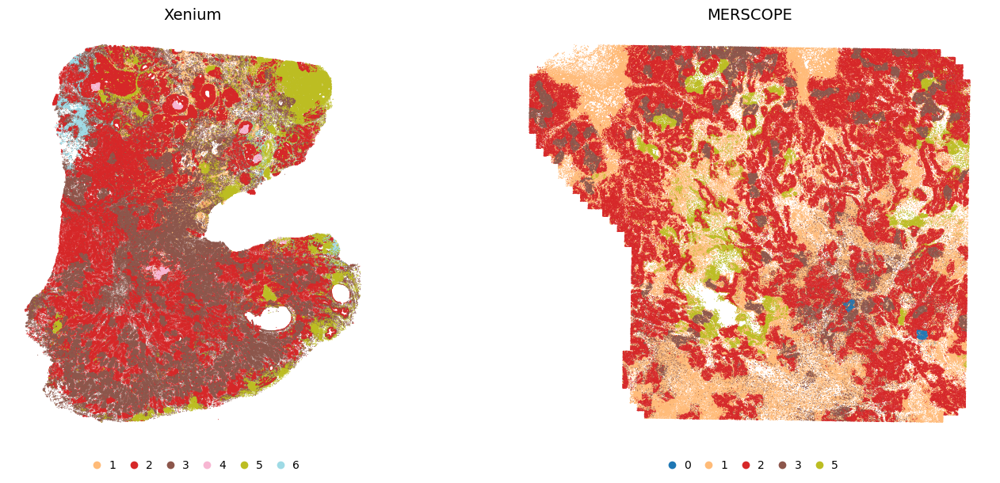


=== niche_k10 ===


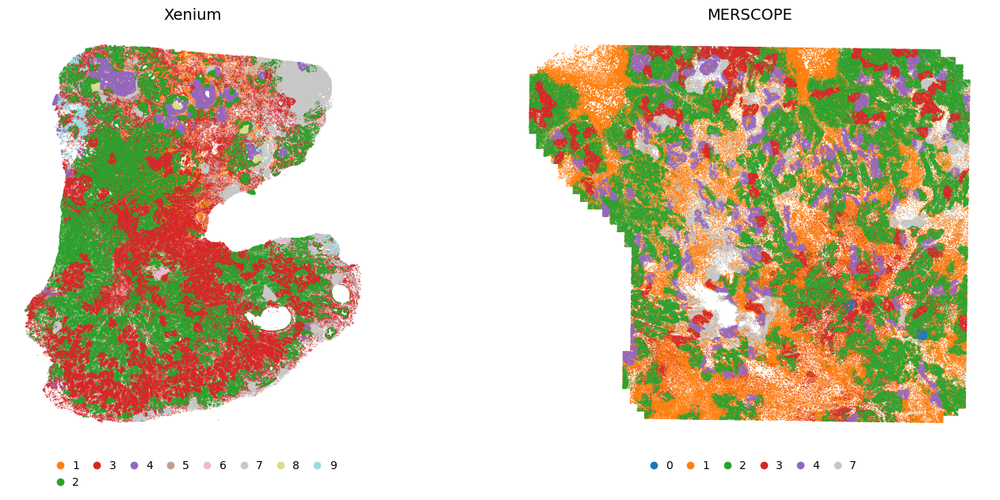


=== niche_k14 ===


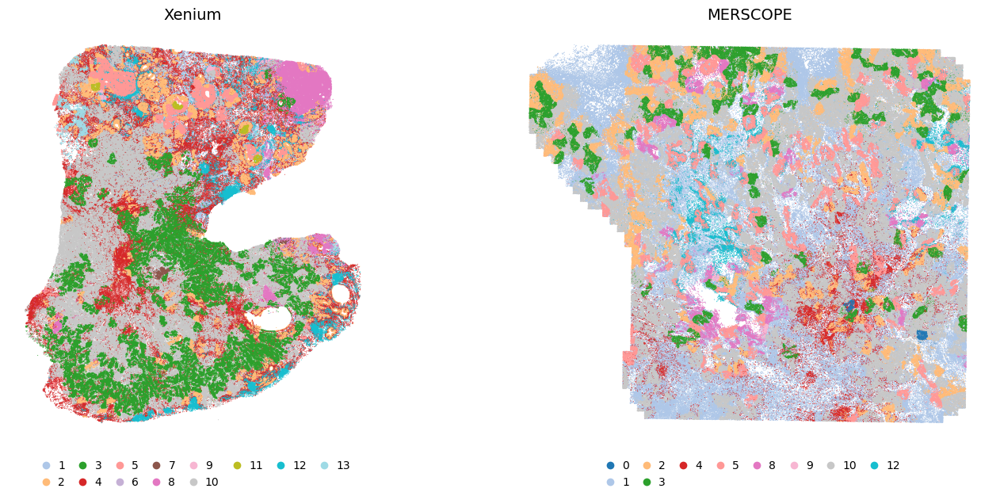


=== niche_k15 ===


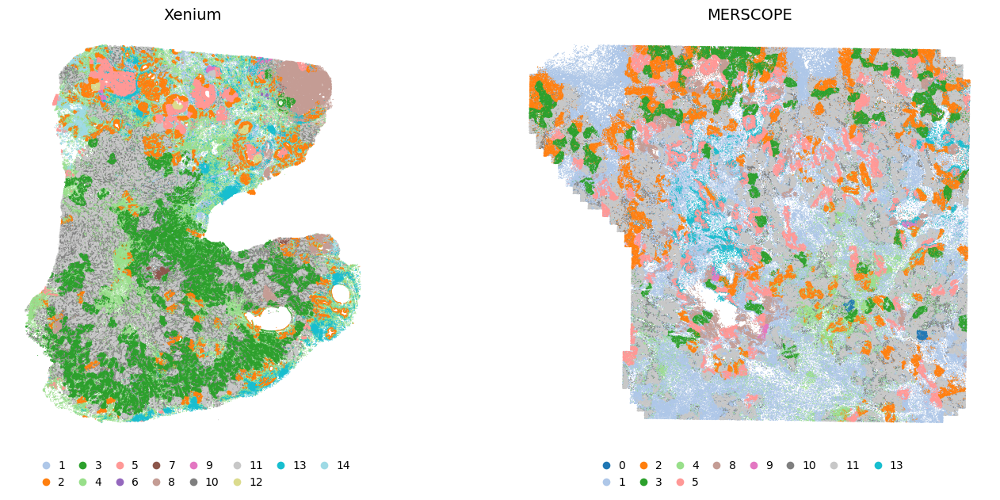

In [24]:
for k in hier["summary"].index:
    key = f"niche_k{k}"
    print(f"\n=== {key} ===")
    plot_sections(sections, key, f"{key}_random")

In [25]:
display(evaluate(sections, [f"niche_k{k}" for k in (7, 10, 14, 15)], PLAT, knn=6))

,n_niches,FIDE_Xenium,FIDE_MERSCOPE,FIDE_mean,JSD
key,,,,,
niche_k7,7,0.720645,0.749833,0.735239,0.164702
niche_k10,10,0.765276,0.761335,0.763305,0.170541
niche_k14,14,0.758853,0.722652,0.740752,0.171050
niche_k15,15,0.738844,0.691507,0.715176,0.185756


In [26]:
from scipy.spatial.distance import jensenshannon
import numpy as np, pandas as pd

def jsd_on(sections, key, keep):
    P = []
    for a in sections:
        vc = a.obs[key].astype(str).value_counts()
        p = np.array([vc.get(v, 0) for v in keep], float); P.append(p / p.sum())
    return jensenshannon(P[0], P[1], base=2) ** 2

for k in (7, 10, 15):
    key = f"niche_k{k}"
    tab = pd.crosstab(np.concatenate([a.obs[key].astype(str) for a in sections]),
                      np.concatenate([[p] * a.n_obs for a, p in zip(sections, PLAT)]),
                      normalize="columns")
    pi_x = tab["Xenium"] / tab.sum(1)
    shared = list(pi_x[(pi_x >= 0.15) & (pi_x <= 0.85)].index)
    print(f"k={k}: JSD all = {jsd_on(sections, key, list(tab.index)):.3f} | "
          f"shared only ({len(shared)} niches) = {jsd_on(sections, key, shared):.3f}")

k=7: JSD all = 0.165 | shared only (3 niches) = 0.057
k=10: JSD all = 0.171 | shared only (4 niches) = 0.064
k=15: JSD all = 0.186 | shared only (9 niches) = 0.083


In [30]:
import scanpy as sc, numpy as np, pandas as pd

KEY = "niche_k15"
PLAT = ["Xenium", "MERSCOPE"]
MIN_CELLS = 20

def de_one(a, key):
    X = a.X
    xmax = X.max() if not hasattr(X, "data") else X.data.max()
    ad = sc.AnnData(X=X.copy(), obs=a.obs[[key]].astype(str).copy(), var=pd.DataFrame(index=a.var_names))
    if xmax > 50:                                   # raw counts -> log-normalised
        sc.pp.normalize_total(ad, target_sum=1e4); sc.pp.log1p(ad)
    keep = ad.obs[key].value_counts()
    groups = list(keep[keep >= MIN_CELLS].index)
    ad = ad[ad.obs[key].isin(groups)].copy()
    sc.tl.rank_genes_groups(ad, key, method="wilcoxon", use_raw=False, pts=True)
    out = []
    for g in groups:
        df = sc.get.rank_genes_groups_df(ad, group=g)
        df = df.rename(columns={"names": "gene", "logfoldchanges": "logFC", "pvals_adj": "pval_adj"})
        df["niche"] = g
        df["rank"] = np.arange(len(df))
        out.append(df)
    return pd.concat(out, ignore_index=True)

de = {p: de_one(a, KEY) for p, a in zip(PLAT, sections)}
res = {"de": de}                                    # same structure the plotting scripts expect

In [31]:
path = pd.concat([a.obs[[KEY, f"{KEY}_path"]].astype(str) for a in sections]).drop_duplicates().set_index(KEY)[f"{KEY}_path"]
cnt = pd.DataFrame({p: a.obs[KEY].astype(str).value_counts() for p, a in zip(PLAT, sections)}).fillna(0).astype(int)
q = cnt / cnt.sum()
cnt["pi_Xenium"] = (q["Xenium"] / q.sum(1)).round(2)
cnt["prototypes"] = path

def top(p, g, n=6):
    d = de[p]
    d = d[(d.niche == g) & (d.logFC >= 1) & (d.pval_adj < 0.05)].nsmallest(n, "rank")
    return ", ".join(d.gene)

for p in PLAT:
    cnt[f"top_{p}"] = [top(p, g) for g in cnt.index]
cnt = cnt.loc[sorted(cnt.index, key=int)]
pd.set_option("display.max_colwidth", 120)
display(cnt)

,Xenium,MERSCOPE,pi_Xenium,prototypes,top_Xenium,top_MERSCOPE
niche_k15,,,,,,
0,0,961,0.00,1,,"CR2, VCAM1, FZD7, CIITA, EPHB3, HLA-DMA"
1,14798,188246,0.09,3,"SPARCL1, LUM, CAV1, CXCL12, CCDC80, AQP1","COL1A1, FN1, ACTA2, BST2, TGFB1, TGFBI"
2,56444,77828,0.46,5,"TACSTD2, FLNB, ANKRD30A, KRT7, GATA3, EPCAM","CDH1, EPCAM, MYC, CR2, FOXM1, ERBB3"
3,129697,52592,0.75,6,"TPD52, MUC1, SERPINA3, CLIC6, PGR, FASN","CDH1, CR2, TAPBP, FZD7, LAMB3, CD40"
4,83783,30673,0.76,7,"FCER1G, LYZ, SRGN, LUM, AIF1, CD4","CYBB, CD14, FCGR3A, CSF1R, C1QC, ITGB2"
5,25641,66638,0.31,8,"FLNB, ANKRD30A, MLPH, GATA3, ELOVL5, TACSTD2","MMP7, ICAM1, LAMB3, VEGFA, SPP1, CD40"
6,174,0,1.00,9,"STC2, EGR1, CCND1, KRT7, TACSTD2, PDZK1",
7,1320,0,1.00,10,"RGS5, DSP, DSC2, CCND1, MYLK, KRT14",
8,27961,18533,0.64,11,"MYLK, DST, MYH11, SFRP1, PTN, ACTA2","VEGFA, SPP1, SOD2, CXCL8, SERPINE1, MMP12"


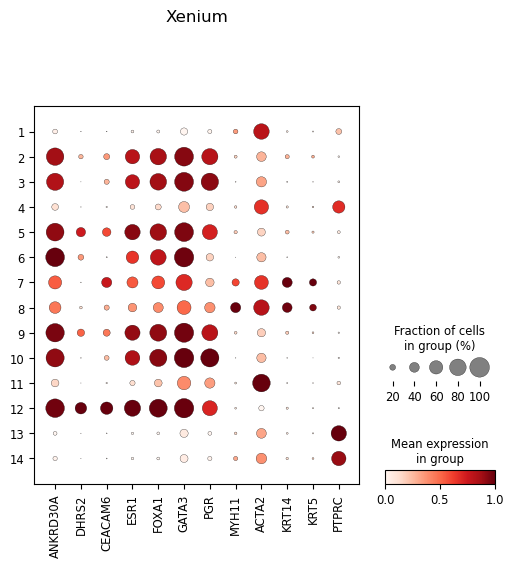

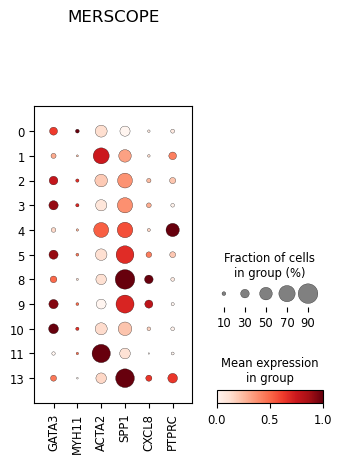

In [33]:
for p, a in zip(PLAT, sections):
    g = [x for x in genes if x in a.var_names]
    ad = a[:, g].copy()
    ad.obs[KEY] = ad.obs[KEY].cat.remove_unused_categories()
    sc.pl.dotplot(ad, g, groupby=KEY, standard_scale="var", title=p)

In [36]:
import scanpy as sc, numpy as np, pandas as pd

LINEAGES = {
    "luminal":       ["ESR1", "FOXA1", "GATA3", "ANKRD30A", "KRT8", "KRT18", "EPCAM", "CDH1"],
    "basal_myoepi":  ["KRT5", "KRT14", "KRT17", "TP63", "OXTR"],
    "fibroblast":    ["LUM", "DCN", "COL1A1", "COL1A2", "POSTN", "PDGFRA", "FBLN1"],
    "pericyte_SMC":  ["RGS5", "PDGFRB", "MYH11", "MCAM", "NOTCH3"],
    "endothelial":   ["PECAM1", "VWF", "CDH5", "KDR", "CLDN5"],
    "myeloid":       ["CD68", "CD14", "LYZ", "CSF1R", "C1QC", "FCGR3A", "AIF1"],
    "T_NK":          ["CD3E", "CD3D", "TRAC", "CD2", "CD8A", "NKG7", "IL7R"],
    "B_plasma":      ["MS4A1", "CD79A", "CD19", "MZB1", "JCHAIN"],
    "mast":          ["CPA3", "TPSAB1", "KIT"],
}

def lineage_labels(a, min_genes=2, z_min=0.5):
    ad = sc.AnnData(X=a.X, obs=pd.DataFrame(index=a.obs_names), var=pd.DataFrame(index=a.var_names))
    used, Z = {}, []
    for lin, genes in LINEAGES.items():
        g = [x for x in genes if x in ad.var_names]
        if len(g) < min_genes:
            continue
        sc.tl.score_genes(ad, g, score_name=lin)
        s = ad.obs[lin].to_numpy()
        Z.append((s - s.mean()) / (s.std() + 1e-8))
        used[lin] = g
    Z = np.vstack(Z).T
    names = np.array(list(used))
    lab = names[Z.argmax(1)].astype(object)
    lab[Z.max(1) < z_min] = "unassigned"
    return lab, used

for p, a in zip(PLAT, sections):
    a.obs["lineage"], used = lineage_labels(a)
    print(p, "| genes used:", {k: len(v) for k, v in used.items()})

for p, a in zip(PLAT, sections):
    comp = pd.crosstab(a.obs["niche_k15"].astype(str), a.obs["lineage"], normalize="index")
    comp = comp.loc[sorted(comp.index, key=int)]
    print(f"\n=== {p}: lineage fraction per niche ===")
    display((comp * 100).round(0).astype(int))

Xenium | genes used: {'luminal': 7, 'basal_myoepi': 3, 'fibroblast': 4, 'pericyte_SMC': 3, 'endothelial': 3, 'myeloid': 6, 'T_NK': 5, 'B_plasma': 4, 'mast': 3}
MERSCOPE | genes used: {'luminal': 3, 'fibroblast': 3, 'pericyte_SMC': 2, 'endothelial': 5, 'myeloid': 6, 'T_NK': 6, 'B_plasma': 4}

=== Xenium: lineage fraction per niche ===


lineage,B_plasma,T_NK,basal_myoepi,endothelial,fibroblast,luminal,mast,myeloid,pericyte_SMC,unassigned
niche_k15,,,,,,,,,,
1,3,8,2,29,27,1,6,3,21,1
2,1,4,14,3,3,42,10,2,6,15
3,1,8,5,4,8,43,3,4,7,18
4,10,11,4,6,17,2,5,38,5,1
5,3,5,12,2,0,43,17,2,6,10
6,1,3,2,10,6,47,3,6,5,17
7,1,3,31,1,3,10,16,1,32,3
8,2,3,40,8,9,10,9,2,14,4
9,1,3,10,3,2,47,9,2,9,14



=== MERSCOPE: lineage fraction per niche ===


lineage,B_plasma,T_NK,endothelial,fibroblast,luminal,myeloid,pericyte_SMC,unassigned
niche_k15,,,,,,,,
0,19,4,4,2,37,4,8,22
1,8,14,10,24,4,19,17,3
2,16,6,5,3,32,13,7,17
3,16,5,7,3,39,3,7,21
4,11,5,3,7,6,60,5,3
5,16,7,6,3,31,12,7,17
8,12,5,7,10,24,11,12,19
9,14,2,4,4,41,5,8,21
10,16,5,6,3,41,2,7,21


In [35]:
print(adata.obs["region"].value_counts().head())

region
region_0    537182
Name: count, dtype: int64


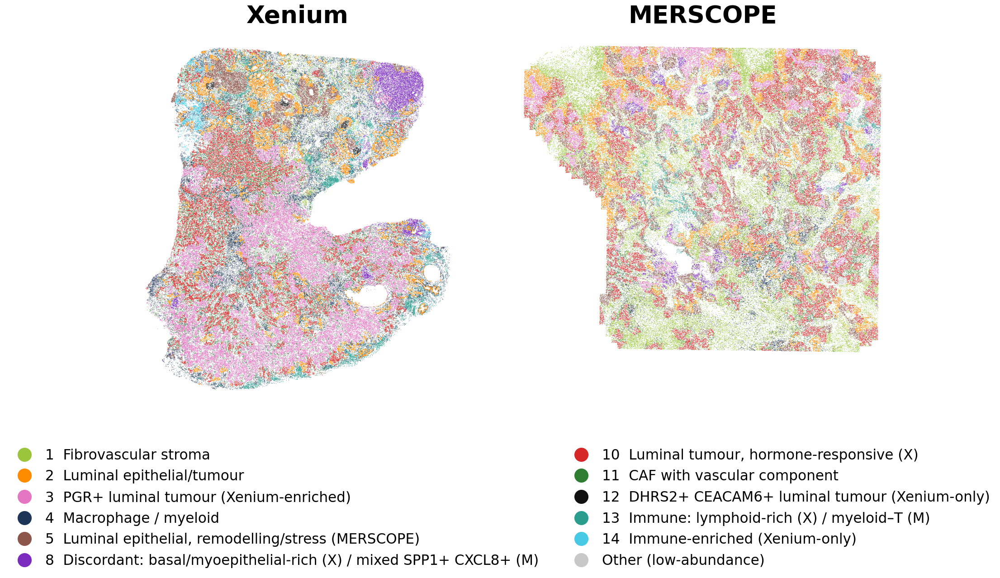

saved -> crossplatform_breast_pretrained/results/fig_spatial_k15.svg/.png/.pdf


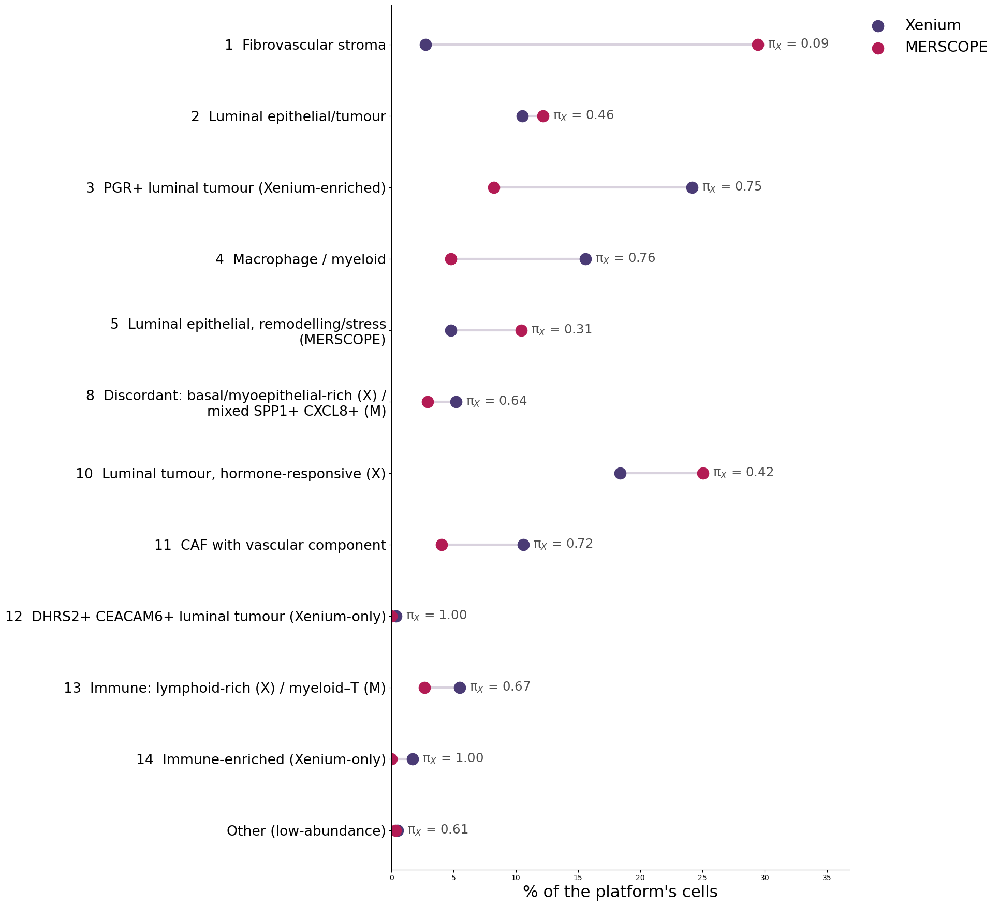

saved -> crossplatform_breast_pretrained/results/fig_composition_k15.svg/.png/.pdf


,Xenium,MERSCOPE,pi_Xenium
1,2.75,29.44,0.09
2,10.51,12.17,0.46
3,24.14,8.23,0.75
4,15.60,4.80,0.76
5,4.77,10.42,0.31
8,5.21,2.90,0.64
10,18.38,25.03,0.42
11,10.61,4.04,0.72
12,0.37,0.00,1.00
13,5.47,2.66,0.67


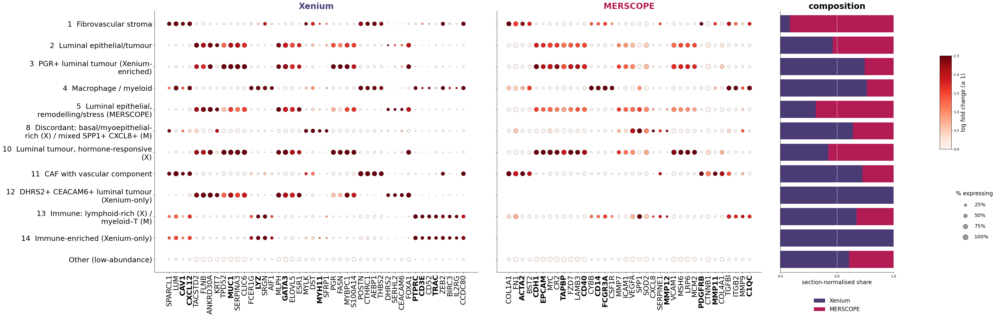

saved -> crossplatform_breast_pretrained/results/fig_markers_k15.svg/.png/.pdf
bold genes are measured on both panels (128 shared); up-regulated markers only (logFC >= 1, padj <= 0.05)


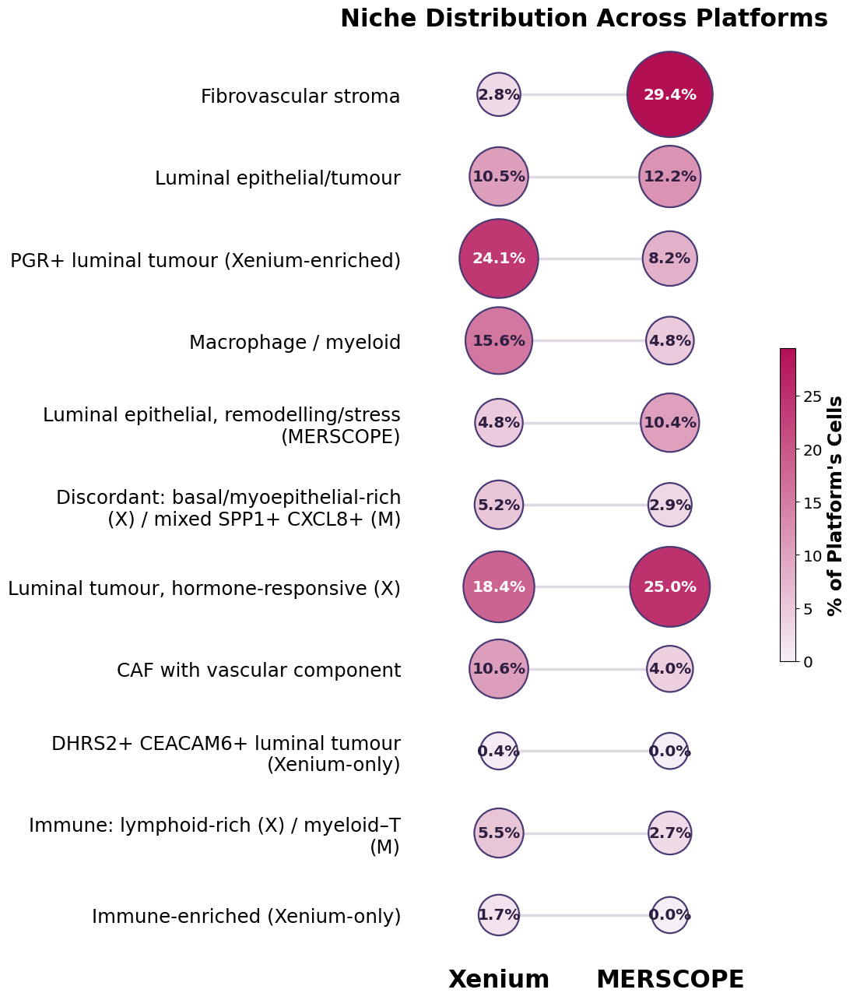

saved -> crossplatform_breast_pretrained/results/fig_distribution_k15.svg/.png/.pdf


In [60]:
# =============================================================================
# Cross-platform niche figures (k = 15). Run in the notebook namespace:
#     %run -i figures_k15.py
# or paste this whole file into one cell.
# Needs from the notebook: sections (list of AnnData, Xenium first), de (dict of
# DE tables per platform, columns niche/gene/logFC/rank/pval_adj), RESULTS_DIR.
# =============================================================================
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from IPython.display import display

mpl.rcParams.update({"svg.fonttype": "none", "font.family": "DejaVu Sans"})

SRC_KEY = "niche_k15"
KEY = "niche_k15_fig"
OTHER = {"0", "6", "7", "9"}          # low-abundance niches grouped as "Other"
PLAT = ["Xenium", "MERSCOPE"]
OUT = Path(RESULTS_DIR)
OUT.mkdir(parents=True, exist_ok=True)

for _a in sections:
    _s = _a.obs[SRC_KEY].astype(str)
    _a.obs[KEY] = _s.where(~_s.isin(OTHER), "Other")

annot = {
    "1":  "Fibrovascular stroma",
    "2":  "Luminal epithelial/tumour",
    "3":  "PGR+ luminal tumour (Xenium-enriched)",
    "4":  "Macrophage / myeloid",
    "5":  "Luminal epithelial, remodelling/stress (MERSCOPE)",
    "8":  "Discordant: basal/myoepithelial-rich (X) / mixed SPP1+ CXCL8+ (M)",
    "10": "Luminal tumour, hormone-responsive (X)",
    "11": "CAF with vascular component",
    "12": "DHRS2+ CEACAM6+ luminal tumour (Xenium-only)",
    "13": "Immune: lymphoid-rich (X) / myeloid–T (M)",
    "14": "Immune-enriched (Xenium-only)",
    "Other": "Other (low-abundance)",
}
COLORS = {
    "2":  "#FF8C00",   # luminal epithelial       – orange
    "10": "#D62728",   # luminal hormone-resp.    – red
    "3":  "#E377C2",   # PGR+ Xenium-enriched     – pink
    "5":  "#8C564B",   # remodelling/stress       – brown
    "12": "#111111",   # DHRS2+ CEACAM6+          – black
    "8":  "#7B2CBF",   # discordant               – purple
    "1":  "#9BC53D",   # fibrovascular            – light green
    "11": "#2E7D32",   # CAF + vascular           – dark green
    "4":  "#1D3557",   # macrophage/myeloid       – navy
    "13": "#2A9D8F",   # lymphoid/myeloid–T       – teal
    "14": "#48CAE4",   # immune-enriched (X)      – sky blue
    "Other": "#C8C8C8",
}
SPOT = 0.5          # spatial point size
SVG_DPI = 150       # resolution of the rasterised points inside SVGs (file size scales ~ dpi^2)
PNG_DPI = 150
SPATIAL_MAX_CELLS = 250_000   # per section, spatial map only (None = all cells)
N_GENES = 4         # markers per niche in the dot plot
MIN_LFC = 1.0
FS = 1.6            # font scale: 1.0 = original, raise for larger text
MAX_PADJ = 0.05
XEN_COL, MER_COL = "#4A3B75", "#B31B54"


def _labels(a):
    return a.obs[KEY].astype(str).to_numpy()


def _cats():
    return sorted(set().union(*[set(_labels(a)) for a in sections]),
                  key=lambda c: (c == "Other", int(c) if c.isdigit() else 0))


def _expr(a, gene):
    j = a.var_names.get_loc(gene)
    v = a.X[:, j]
    return np.asarray(v.todense()).ravel() if hasattr(v, "todense") else np.asarray(v).ravel()


def _label(c, width=None):
    s = annot.get(c, f"niche {c}")
    return "\n".join(textwrap.wrap(s, width)) if width else s


def _tick(c, width=None):
    return _label(c, width) if c == "Other" else f"{c}  {_label(c, width)}"


def _save(fig, stem):
    fig.savefig(OUT / f"{stem}.svg", dpi=SVG_DPI)
    fig.savefig(OUT / f"{stem}.png", dpi=PNG_DPI, bbox_inches="tight")
    fig.savefig(OUT / f"{stem}.pdf", dpi=SVG_DPI)
    display(fig)
    plt.close(fig)
    print(f"saved -> {OUT / stem}.svg/.png/.pdf")


cats = _cats()
col = {c: COLORS.get(c, mpl.colormaps["tab20"](i % 20)) for i, c in enumerate(cats)}

# composition: % of each platform's cells, and section-normalised Xenium share
pct = pd.DataFrame({p: pd.Series(_labels(a)).value_counts(normalize=True) * 100
                    for p, a in zip(PLAT, sections)}).reindex(cats).fillna(0)
pi_x = pct[PLAT[0]] / pct.sum(axis=1)

# ---------------------------------------------------------------- 1. spatial
fig, axes = plt.subplots(1, len(sections), figsize=(9 * len(sections), 11 + 3 * (FS - 1)), facecolor="white")
for ax, a, p in zip(axes, sections, PLAT):
    xy = np.asarray(a.obsm["spatial"])
    lab = _labels(a)
    if SPATIAL_MAX_CELLS and len(lab) > SPATIAL_MAX_CELLS:
        keep = np.random.default_rng(0).choice(len(lab), SPATIAL_MAX_CELLS, replace=False)
        xy, lab = xy[keep], lab[keep]
    ax.scatter(xy[:, 0], xy[:, 1], c=[col[l] for l in lab], s=SPOT, linewidths=0, rasterized=True)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_anchor("N")
    ax.set_title(p, fontsize=24 * FS, fontweight="bold", pad=12)
fig.legend(handles=[Line2D([], [], marker="o", ls="", ms=14 * FS, mfc=col[c], mew=0,
                           label=_tick(c)) for c in cats],
           loc="lower center", ncol=2, frameon=False, fontsize=14 * FS,
           bbox_to_anchor=(0.5, 0.0), columnspacing=2.0, handletextpad=0.5)
fig.subplots_adjust(left=0.01, right=0.99, top=0.95, bottom=0.30, wspace=0.03)
_save(fig, "fig_spatial_k15")

# ------------------------------------------------- 2. composition (dumbbell)
fig, ax = plt.subplots(figsize=(13 + 4 * FS, (0.75 * len(cats) + 2) * FS), facecolor="white")
y = np.arange(len(cats))
for i, c in enumerate(cats):
    ax.plot(pct.loc[c, PLAT], [i, i], color="#D9D2DE", lw=3, zorder=1)
ax.scatter(pct[PLAT[0]], y, s=160 * FS, color=XEN_COL, label=PLAT[0], zorder=2)
ax.scatter(pct[PLAT[1]], y, s=160 * FS, color=MER_COL, label=PLAT[1], zorder=2)
for i, c in enumerate(cats):
    ax.text(pct.loc[c].max() + 0.8, i, f"π$_X$ = {pi_x[c]:.2f}", va="center", fontsize=11 * FS, color="0.3")
ax.set_yticks(y)
ax.set_yticklabels([_tick(c, 46) for c in cats], fontsize=12 * FS)
ax.invert_yaxis()
ax.set_xlabel("% of the platform's cells", fontsize=14 * FS)
ax.set_xlim(0, pct.to_numpy().max() * 1.25)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(frameon=False, fontsize=13 * FS, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout()
_save(fig, "fig_composition_k15")
display(pct.assign(pi_Xenium=pi_x).round(2))

# ------------------------------- 3. marker dot plot (native panels) + composition
def _top_genes(d):
    q = (d.logFC >= MIN_LFC) & (d.pval_adj <= MAX_PADJ)
    genes = []
    for c in cats:
        ranked = d[q & (d.niche.astype(str) == c)].sort_values("rank").gene
        genes += [g for g in ranked if g not in genes][:N_GENES]
    return genes

shared = set(sections[0].var_names)
for a in sections[1:]:
    shared &= set(a.var_names)
gene_lists = [_top_genes(de[p]) for p in PLAT]
widths = [max(len(g), 1) for g in gene_lists] + [max(map(len, gene_lists)) * 0.35]
fig = plt.figure(figsize=(sum(widths) * 0.36 + 12, 0.75 * len(cats) + 6), facecolor="white")
gs = GridSpec(1, len(PLAT) + 1, figure=fig, width_ratios=widths, wspace=0.08)
sc_last = None
for pi_, (a, p, genes) in enumerate(zip(sections, PLAT, gene_lists)):
    ax = fig.add_subplot(gs[pi_])
    lab = _labels(a)
    lfc = {(str(r.niche), r.gene): r.logFC for r in de[p].itertuples()}
    xs, ys, ss, cs = [], [], [], []
    for gi, g in enumerate(genes):
        v = _expr(a, g)
        for ci, c in enumerate(cats):
            m = lab == c
            if not m.any():
                continue
            xs.append(gi); ys.append(ci)
            ss.append(max((v[m] > 0).mean(), 0.02) * 220)
            cs.append(max(lfc.get((c, g), 0.0), 0.0))
    sc_last = ax.scatter(xs, ys, s=ss, c=cs, cmap="Reds", vmin=0, vmax=2.5,
                         edgecolor="0.3", linewidth=0.4, rasterized=False)
    ax.set_xticks(range(len(genes)))
    ax.set_xticklabels(genes, rotation=90, fontsize=13 * FS)
    for t, g in zip(ax.get_xticklabels(), genes):
        if g in shared:
            t.set_fontweight("bold")
    ax.set_ylim(-0.6, len(cats) - 0.4); ax.invert_yaxis()
    ax.set_yticks(range(len(cats)))
    ax.set_yticklabels([_tick(c, 34) for c in cats] if pi_ == 0 else [], fontsize=13 * FS)
    ax.set_title(p, fontsize=15 * FS, fontweight="bold", color=XEN_COL if pi_ == 0 else MER_COL)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axc = fig.add_subplot(gs[-1])
axc.barh(np.arange(len(cats)), pi_x.values, color=XEN_COL, label=PLAT[0])
axc.barh(np.arange(len(cats)), 1 - pi_x.values, left=pi_x.values, color=MER_COL, label=PLAT[1])
axc.axvline(0.5, ls="--", lw=1, color="white")
axc.set_ylim(-0.6, len(cats) - 0.4); axc.invert_yaxis(); axc.set_yticks([])
axc.set_xlim(0, 1); axc.set_xticks([0, 0.5, 1])
axc.set_title("composition", fontsize=15 * FS, fontweight="bold")
axc.set_xlabel("section-normalised share", fontsize=10 * FS)
axc.legend(frameon=False, fontsize=10 * FS, loc="upper center", bbox_to_anchor=(0.5, -0.08))
for s in ("top", "right"):
    axc.spines[s].set_visible(False)
cb = fig.colorbar(sc_last, cax=fig.add_axes([0.92, 0.55, 0.01, 0.25]))
cb.solids.set_rasterized(False)   # keep the gradient vector (BioRender drops embedded images)
cb.set_label(f"log fold change (≥ {MIN_LFC:g})", fontsize=10 * FS)
lax = fig.add_axes([0.91, 0.15, 0.06, 0.3]); lax.axis("off")
for f in (0.25, 0.5, 0.75, 1.0):
    lax.scatter([], [], s=f * 220, c="0.6", edgecolor="0.3", label=f"{int(f * 100)}%")
lax.legend(title="% expressing", frameon=False, fontsize=9 * FS, title_fontsize=10 * FS, labelspacing=1.2)
fig.subplots_adjust(left=0.24, right=0.88, bottom=0.22, top=0.92)
_save(fig, "fig_markers_k15")
print(f"bold genes are measured on both panels ({len(shared)} shared); "
      f"up-regulated markers only (logFC >= {MIN_LFC:g}, padj <= {MAX_PADJ:g})")

# ------------------------------------ 4. niche distribution bubbles (panel e style)
from matplotlib.colors import LinearSegmentedColormap

bcats = [c for c in cats if c != "Other"]    # "Other" not shown in this panel
M = pct.loc[bcats, PLAT].to_numpy()          # % of each platform's cells
bub_cmap = LinearSegmentedColormap.from_list("SharpPurple", ["#F5EEF6", "#B31054"])
fig, ax = plt.subplots(figsize=(11, 0.95 * len(bcats) + 2.5), facecolor="white")
for i in range(len(bcats)):
    ax.plot([0, 1], [i, i], color="#DED8E1", lw=2.5, zorder=0)
X, Y = np.meshgrid(range(len(PLAT)), range(len(bcats)))
sizes = M / M.max() * 3200 * FS + 700 * FS
sc_b = ax.scatter(X.ravel(), Y.ravel(), s=sizes.ravel(), c=M.ravel(), cmap=bub_cmap,
                  vmin=0, vmax=M.max(), edgecolor="#4A3B75", linewidth=1.6, zorder=2)
for i in range(len(bcats)):
    for j in range(len(PLAT)):
        v = M[i, j]
        ax.text(j, i, f"{v:.1f}%", ha="center", va="center", fontsize=9 * FS,
                fontweight="bold", color="white" if v > M.max() * 0.55 else "#2D1E40", zorder=3)
ax.set_xticks(range(len(PLAT)))
ax.set_xticklabels(PLAT, fontsize=14 * FS, fontweight="bold")
ax.set_yticks(range(len(bcats)))
ax.set_yticklabels([_label(c, 38) for c in bcats], fontsize=11 * FS)
ax.invert_yaxis()
ax.set_xlim(-0.55, 1.55)
ax.set_ylim(len(bcats) - 0.4, -0.6)
for s_ in ax.spines.values():
    s_.set_visible(False)
ax.tick_params(length=0)
ax.set_title("Niche Distribution Across Platforms", fontsize=14 * FS, fontweight="bold", pad=18)
cb = fig.colorbar(sc_b, ax=ax, fraction=0.04, pad=0.04, shrink=0.55)
cb.solids.set_rasterized(False)
cb.set_label("% of Platform's Cells", fontsize=11 * FS, fontweight="bold")
cb.ax.tick_params(labelsize=9 * FS)
fig.tight_layout()
_save(fig, "fig_distribution_k15")

UMAP on 120,000 cells x 14 prototypes (niche attention)...


/home/tower4/miniconda3/envs/hebi/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


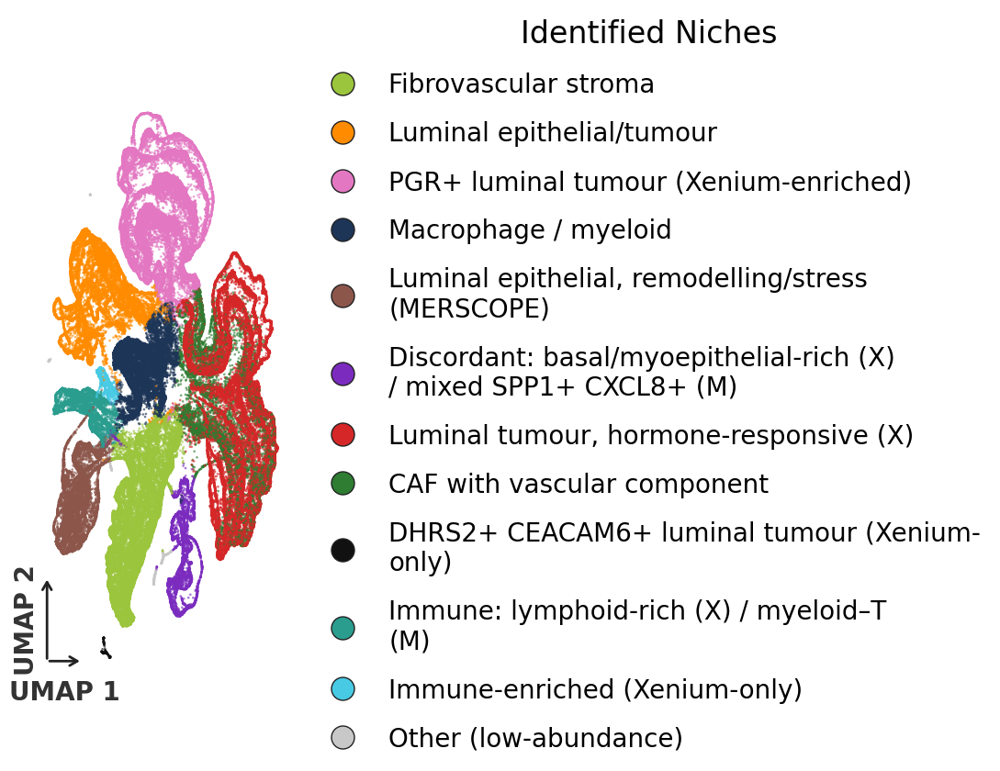

saved -> crossplatform_breast_pretrained/results/umap_hebi_attention_niche_k15.svg/.png


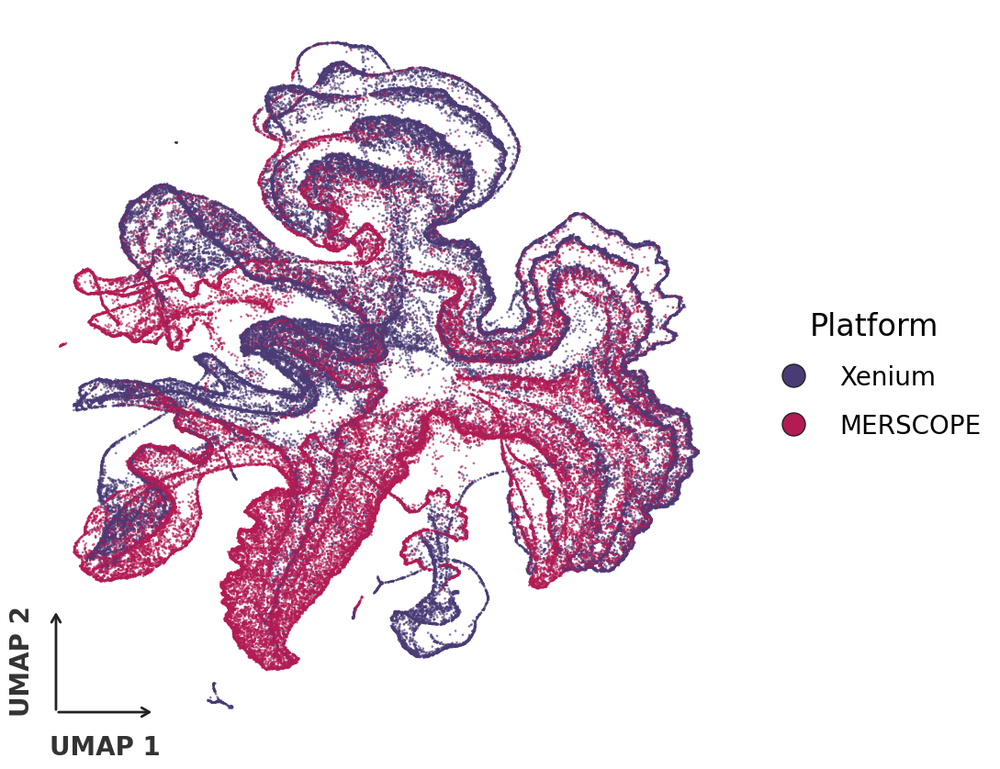

saved -> crossplatform_breast_pretrained/results/umap_hebi_attention_platform.svg/.png


In [51]:
from sklearn.preprocessing import normalize

# same subsample as the z2 UMAP (same seed, same draws)
rng = np.random.default_rng(SEED)
A, plat_a, niche_a = [], [], []
for a, p in zip(sections, PLAT):
    idx = rng.choice(a.n_obs, min(N_SUB, a.n_obs), replace=False)
    A.append(np.asarray(a.obsm["niche_attention"])[idx])
    plat_a.append(np.full(len(idx), p, dtype=object))
    niche_a.append(a.obs[KEY].astype(str).to_numpy()[idx])
A, plat_a, niche_a = np.concatenate(A), np.concatenate(plat_a), np.concatenate(niche_a)

A = A[:, A.sum(0) > 0]                       # drop prototypes never attended to
H = np.sqrt(normalize(A, norm="l1"))         # Hellinger embedding of the attention profile

print(f"UMAP on {H.shape[0]:,} cells x {H.shape[1]} prototypes (niche attention)...")
U_a = umap.UMAP(n_neighbors=35, min_dist=0.35, metric="euclidean",
                random_state=SEED).fit_transform(H)

order_a = rng.permutation(len(U_a))
order_a = np.concatenate([order_a[niche_a[order_a] == "Other"],
                          order_a[niche_a[order_a] != "Other"]])

for colour_by, stem in [("niche", "umap_hebi_attention_niche_k15"),
                        ("platform", "umap_hebi_attention_platform")]:
    fig, ax = plt.subplots(figsize=(11, 8.5))
    c = ([col[n] for n in niche_a[order_a]] if colour_by == "niche"
         else [PLAT_COL[p] for p in plat_a[order_a]])
    ax.scatter(U_a[order_a, 0], U_a[order_a, 1], c=c,
               s=3.5, linewidths=0, alpha=0.65, rasterized=True)
    _add_corner_axes(ax, fontsize=FONT - 5)
    if colour_by == "niche":
        _legend(ax, [_dot(col[k], "\n".join(textwrap.wrap(annot.get(k, k), 40))) for k in cats],
                "Identified Niches")
    else:
        _legend(ax, [_dot(PLAT_COL[p], p) for p in PLAT], "Platform")
    plt.tight_layout()
    _save(fig, stem)

leaves mapped: 14 | purity: 1.0


/home/tower4/miniconda3/envs/hebi/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


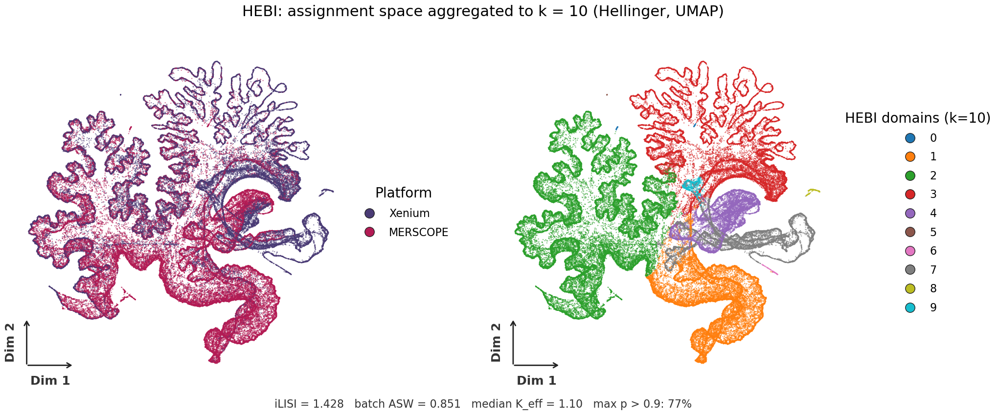

saved -> crossplatform_breast_pretrained/results/assign_space_hebi_k10_umap.svg/.png and metrics csv


model,HEBI
k,10.0000
cells_per_section,60000.0000
iLISI,1.4277
iLISI_onehot,1.6992
batch_ASW,0.8510
H_norm_median,0.0415
K_eff_median,1.1000
frac_maxp_gt_0.9,0.7716
dropped_mass_mean,-0.0000
argmax_vs_hard_agreement,0.9977


In [53]:
from assign_space import mapping_from_labels, run_assignment_space

PLAT = ["Xenium", "MERSCOPE"]
P_list   = [np.asarray(a.obsm["niche_attention"]) for a in sections]
dom_list = [a.obs["niche_k10"].astype(str).to_numpy() for a in sections]

l2d, purity = mapping_from_labels(np.concatenate([P.argmax(1) for P in P_list]),
                                  np.concatenate(dom_list))
print("leaves mapped:", len(l2d), "| purity:", purity)       # purity must be 1.0

met_hebi, E_hebi = run_assignment_space(P_list, l2d, dom_list, PLAT, "HEBI",
                                        out_dir=RESULTS_DIR, method="umap")
display(met_hebi.T)

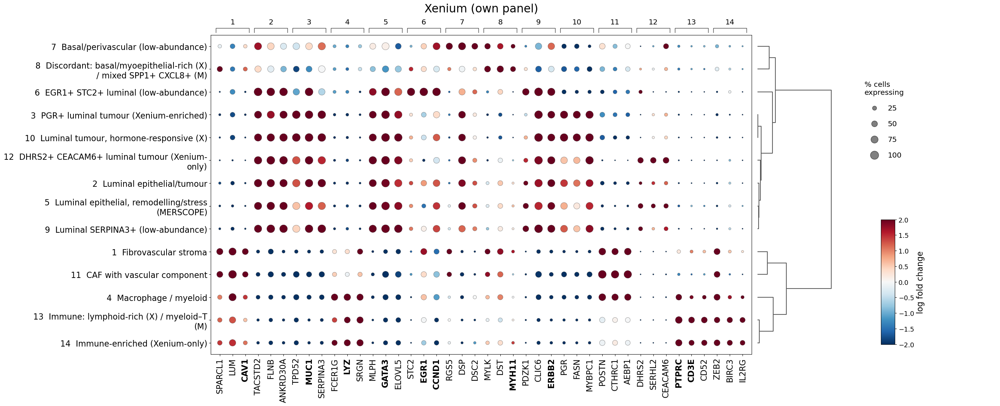

saved -> crossplatform_breast_pretrained/results/supp_markers_xenium_k15.svg/.pdf/.png


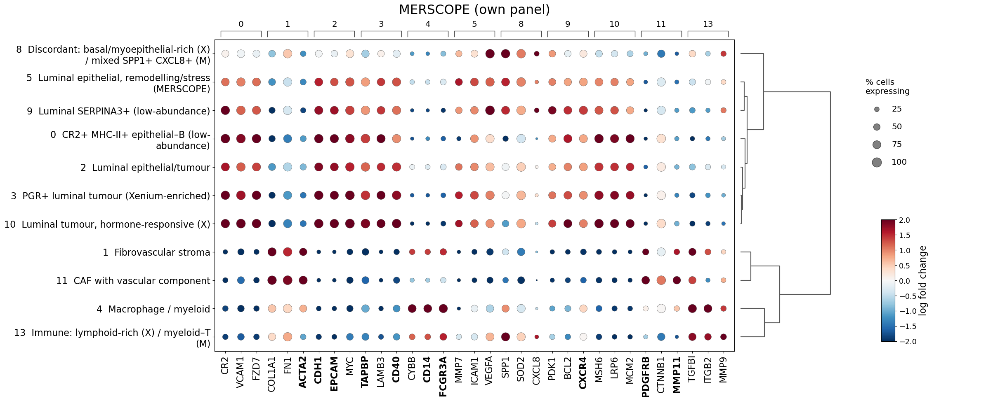

saved -> crossplatform_breast_pretrained/results/supp_markers_merscope_k15.svg/.pdf/.png


In [61]:
# ===================== suppB: full marker profiles per platform (k = 15) =====================
import textwrap
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.cluster.hierarchy import linkage, dendrogram
from IPython.display import display

mpl.rcParams.update({"svg.fonttype": "none", "font.family": "DejaVu Sans"})
KEY, PLAT = "niche_k15", ["Xenium", "MERSCOPE"]
OUT = Path(RESULTS_DIR); OUT.mkdir(parents=True, exist_ok=True)
N_GENES, MIN_LFC, MAX_PADJ, FS, DOT = 3, 1.0, 0.05, 1.6, 260

SUPP_ANNOT = {
    "0":  "CR2+ MHC-II+ epithelial–B (low-abundance)",
    "1":  "Fibrovascular stroma",
    "2":  "Luminal epithelial/tumour",
    "3":  "PGR+ luminal tumour (Xenium-enriched)",
    "4":  "Macrophage / myeloid",
    "5":  "Luminal epithelial, remodelling/stress (MERSCOPE)",
    "6":  "EGR1+ STC2+ luminal (low-abundance)",
    "7":  "Basal/perivascular (low-abundance)",
    "8":  "Discordant: basal/myoepithelial-rich (X) / mixed SPP1+ CXCL8+ (M)",
    "9":  "Luminal SERPINA3+ (low-abundance)",
    "10": "Luminal tumour, hormone-responsive (X)",
    "11": "CAF with vascular component",
    "12": "DHRS2+ CEACAM6+ luminal tumour (Xenium-only)",
    "13": "Immune: lymphoid-rich (X) / myeloid–T (M)",
    "14": "Immune-enriched (Xenium-only)",
}
shared = set(sections[0].var_names) & set(sections[1].var_names)


def _expr(a, g):
    v = a.X[:, a.var_names.get_loc(g)]
    return np.asarray(v.todense()).ravel() if hasattr(v, "todense") else np.asarray(v).ravel()


def supp_dotplot(a, d, pname, vmax=2.0):
    lab = a.obs[KEY].astype(str).to_numpy()
    niches = sorted(set(lab), key=int)
    q = (d.logFC >= MIN_LFC) & (d.pval_adj <= MAX_PADJ)
    genes, spans = [], []
    for c in niches:
        ranked = d[q & (d.niche.astype(str) == c)].sort_values("rank").gene
        new = [g for g in ranked if g not in genes][:N_GENES]
        if new:
            spans.append((c, len(genes), len(genes) + len(new) - 1))
        genes += new
    expr = {g: _expr(a, g) for g in genes}
    masks = {c: lab == c for c in niches}
    prof = np.array([[expr[g][masks[c]].mean() for g in genes] for c in niches])
    Z = linkage(prof, method="average", metric="correlation")
    niches_ord = [niches[i] for i in dendrogram(Z, no_plot=True)["leaves"]]
    lfc = {(str(r.niche), r.gene): r.logFC for r in d.itertuples()}

    fig = plt.figure(figsize=(0.42 * len(genes) + 14, 0.62 * len(niches) + 5), facecolor="white")
    # everything inside the figure: dot plot | dendrogram | (colourbar + size key at right)
    gs = GridSpec(1, 2, figure=fig, width_ratios=[len(genes) * 0.5, 3], wspace=0.02,
                  left=0.30, right=0.84, top=0.84, bottom=0.20)
    ax = fig.add_subplot(gs[0])
    xs, ys, ss, cs = [], [], [], []
    for gi, g in enumerate(genes):
        for ni, c in enumerate(niches_ord):
            xs.append(gi); ys.append(ni)
            ss.append(max((expr[g][masks[c]] > 0).mean(), 0.02) * DOT)
            cs.append(lfc.get((c, g), 0.0))
    sc_ = ax.scatter(xs, ys, s=ss, c=cs, cmap="RdBu_r", vmin=-vmax, vmax=vmax,
                     edgecolor="0.3", linewidth=0.4)
    ax.set_xticks(range(len(genes)))
    ax.set_xticklabels(genes, rotation=90, fontsize=10 * FS)
    for t, g in zip(ax.get_xticklabels(), genes):
        if g in shared:
            t.set_fontweight("bold")
    ax.set_yticks(range(len(niches_ord)))
    ax.set_yticklabels([f"{c}  {textwrap.fill(SUPP_ANNOT.get(c, c), 40)}" for c in niches_ord],
                       fontsize=10 * FS)
    ax.set_xlim(-0.7, len(genes) - 0.3)
    ax.set_ylim(-0.5, len(niches_ord) - 0.5)
    ax.invert_yaxis()
    ax.set_title(f"{pname} (own panel)", fontsize=14 * FS, pad=45)
    for c, x0, x1 in spans:
        ax.plot([x0 - 0.3, x0 - 0.3, x1 + 0.3, x1 + 0.3], [-0.6, -0.8, -0.8, -0.6],
                color="0.25", lw=1.0, clip_on=False)
        ax.text((x0 + x1) / 2, -0.9, c, ha="center", va="bottom", fontsize=9 * FS, clip_on=False)

    axd = fig.add_subplot(gs[1])
    dendrogram(Z, orientation="right", ax=axd, no_labels=True, link_color_func=lambda k: "0.35")
    axd.set_ylim(10 * len(niches_ord), 0)
    axd.axis("off")

    cb = fig.colorbar(sc_, cax=fig.add_axes([0.88, 0.22, 0.012, 0.25]))
    cb.solids.set_rasterized(False)
    cb.set_label("log fold change", fontsize=10 * FS)
    cb.ax.tick_params(labelsize=8 * FS)
    lax = fig.add_axes([0.86, 0.52, 0.12, 0.30]); lax.axis("off")
    for f in (0.25, 0.5, 0.75, 1.0):
        lax.scatter([], [], s=f * DOT, c="0.5", edgecolor="0.3", label=f"{int(f * 100)}")
    lax.legend(title="% cells\nexpressing", fontsize=9 * FS, title_fontsize=9 * FS,
               frameon=False, labelspacing=1.2, loc="center left")

    stem = OUT / f"supp_markers_{pname.lower()}_k15"
    fig.savefig(f"{stem}.svg", bbox_inches="tight")
    fig.savefig(f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(f"{stem}.png", dpi=150, bbox_inches="tight")
    display(fig)
    plt.close(fig)
    print(f"saved -> {stem}.svg/.pdf/.png")


for a, p in zip(sections, PLAT):
    supp_dotplot(a, de[p], p)

In [59]:
from sklearn.neighbors import NearestNeighbors
a = sections[0]
lab = a.obs["niche_k15"].astype(str).to_numpy()
idx = NearestNeighbors(n_neighbors=7).fit(a.obsm["spatial"]).kneighbors(a.obsm["spatial"], return_distance=False)[:, 1:]
m = lab == "12"
print("niche 12: fraction of spatial neighbours also in 12 =",
      round(float((lab[idx[m]] == "12").mean()), 3), "| expected if random =", round(float(m.mean()), 4))

niche 12: fraction of spatial neighbours also in 12 = 0.921 | expected if random = 0.0037
